# BraMex Team Notebook
MITxT 2.980x Sports Analytics, Soccer project

Team: Leonardo De Andrade (PM and integration lead), Monica D. Morales-Hernandez (modeling lead), Pablo Saraiva (evaluation and validation lead)

Project question: what does physical exertion buy in a football match? We use 25 Hz tracking and event data from six DFL matches. The final model is evaluated on a match we have not seen.

All team work goes into this notebook. Each part lists its owner, what it delivers and what the next part needs from it. Each owner writes the code for their part.

## How to use this notebook

### Structure

| Part | Owner | Delivers |
|---|---|---|
| 1. Setup and configuration | Leonardo | Environment, paths, agreed parameters, holdout guard |
| 2. Data loading | Leonardo | Raw data for every match, cached |
| 3. Shared tables | Leonardo, Monica | The four standard tables every workstream uses |
| 4. Data checks | Pablo | Checks that must pass before any analysis |
| 5. Workstream A: players and physical load | Leonardo | Findings and features |
| 6. Workstream B: team possession, progression and defense | Monica | Findings and features |
| 7. Workstream C: chances and possession changes | Pablo | Findings and features |
| 8. Integration | Leonardo | One feature table from all workstreams |
| 9. Prediction | Monica, Pablo | Validated, frozen model |
| 10. Holdout inference | Pablo | Predictions on the unseen match |
| 11. Results log | All | Every claim with its evidence |
| 12. Conclusions and limitations | All | What we can and cannot say |

### Team rules
1. Work only in your own part. Changes to Parts 1 to 4 need the PM's agreement first, since every result depends on them.
2. Parameters come from the decision log. Workstreams read thresholds, windows and model settings from the configuration in Part 1 instead of typing them.
3. Everyone uses the tables from Part 3, not their own copy of the raw files.
4. The holdout match stays closed until the models are frozen (Part 9.8).
5. Every claim has an evidence label and goes into the results log (Part 11).
6. Clear all outputs before committing. Results stay inside the team until we review them.

### Evidence labels

| Label | Meaning |
|---|---|
| Descriptive | What the data shows, no relationship claimed |
| Association | Two quantities move together within the stated unit and controls |
| Robust association | The association holds across matches, alternative definitions and placebo tests |
| Predictive (out-of-match) | Beats a baseline on matches the model did not see |
| Causal (not claimed) | Used only to say explicitly that we do not claim causality |

## 1. Setup and configuration
Owner: Leonardo

Delivers: a working environment and one configuration object used by every part.

### 1.1 Environment
The notebook must run from top to bottom on each member's machine or on Google Colab.
- Python 3.11+ with `floodlight 1.2.0`, `numpy`, `pandas`, `scipy`, `scikit-learn`, `statsmodels`, `matplotlib`.
- Imports, display options (no scientific notation in outputs) and a fixed random seed.

How to run it:
- **Local (Anaconda, venv):** from the repository root run `pip install -e .` once, then open this notebook from the `notebooks` folder.
- **Google Colab:** run the cell below. It installs the package from GitHub. The data folder is set in 1.2.
- **Other hosted notebooks (Kaggle, Deepnote, SageMaker):** same as Colab. Upload the XML files and point 1.2 to their folder.

Shared code lives in `src/bramex`. Parts 1 to 4 only call it, so everyone runs exactly the same pipeline.

In [1]:
# Install the shared package if it is not available yet (Colab, Kaggle or a fresh local environment)
import os, sys, subprocess
from pathlib import Path

REPO_URL = "https://github.com/leonardoeng13/bramex-football-exertion-pitch-control.git"
try:
    import bramex
except ImportError:
    local_src = Path.cwd().parent / "src"
    if (local_src / "bramex").exists():
        # Local clone without `pip install -e .`: use the source folder directly
        sys.path.insert(0, str(local_src))
    else:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", f"git+{REPO_URL}"], check=True)
    import bramex

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from bramex import CONFIG

RNG = np.random.default_rng(2980)
print("bramex", bramex.__version__)

bramex 0.1.0


### 1.2 Paths
The data folder comes from the environment variable `BRAMEX_DATA_DIR`, so paths are not edited in the notebook. The cache and model folders are created if missing.

On Colab the cell mounts Google Drive. Put the DFL XML files in `MyDrive/BraMex/data`, or change the path. The cache holds the tables built in Part 3. If one person builds it and shares the cache folder, the others skip the slow step, as long as the parameters are the same.

In [2]:
# Data and cache folders. Locally, set BRAMEX_DATA_DIR before starting Jupyter or write the path in DATA.
DATA, CACHE = None, None
if "google.colab" in sys.modules:
    from google.colab import drive
    drive.mount("/content/drive")
    DATA = "/content/drive/MyDrive/BraMex/data"
    CACHE = "/content/drive/MyDrive/BraMex/cache"

ENV = bramex.setup_environment(data=DATA, cache=CACHE)
MODEL_DIR = Path("models"); MODEL_DIR.mkdir(exist_ok=True)

environment  local
data_dir     C:\Users\pablo\OneDrive\Desktop\curso\atividade time\dados
cache_dir    C:\Users\pablo\OneDrive\Desktop\curso\atividade time\bramex-football-exertion-pitch-control\data\cache\tables_bc95d22aae
data_found   True
python       3.13.2


### 1.3 Parameters from the decision log
One configuration object holds every parameter that affects results. Each value references its decision and status (Proposed or Agreed).

| Decision | Parameter(s) | Owner |
|---|---|---|
| D1 Smoothing of positions | Savitzky-Golay window and order | Leonardo |
| D2 Load metric | HSR, sprint, metabolic power, Ã¢Ë†Â«aÃ‚Â² dt | Leonardo |
| D3 Speed and acceleration thresholds | HSR speed, sprint speed, acceleration | Leonardo |
| D4 Pitch-control model | Voronoi, time-to-arrival or both, plus grid, ball weighting and model parameters | Monica |
| D5 Time windows | Sampling rate and aggregation windows | All |
| D6 Possession definition | DFL flag or own rule | Monica |
| D7 Prediction target and metric | Must match the course's holdout evaluation | All |
| D8 Validation scheme | Leave-one-match-out or alternative | Pablo |

Code: `src/bramex/config.py`. When a decision is agreed at the lab, the PM updates its value and status there. The cache folder name depends on these values, so a change rebuilds the tables automatically.

In [3]:
# Current parameters, their decision-log entry and status
CONFIG.describe()

,value,decision,status,description
parameter,,,,
FRAMERATE,25,-,Fixed,DFL tracking frame rate (Hz)
SMOOTH_WINDOW,13,D1,Proposed,Savitzky-Golay window for positions (frames)
SMOOTH_ORDER,2,D1,Proposed,Savitzky-Golay polynomial order
MAX_SPEED,12.0000,D1,Proposed,Physical speed cap after smoothing (m/s)
MAX_ACC,8.0000,D1,Proposed,Physical acceleration cap after smoothing (m/s2)
HSR_SPEED,5.5000,D3,Proposed,High-speed running threshold (m/s)
SPRINT_SPEED,7.0000,D3,Proposed,Sprint threshold (m/s)
ACC_THRESHOLD,2.5000,D3,Proposed,High acceleration and deceleration threshold (...
SAMPLE_HZ,5,D5,Proposed,Analysis sampling rate (Hz)


### 1.4 Holdout guard
List of match IDs that cannot be loaded before the freeze. Functions that load data must refuse these IDs.

In [4]:
# Match IDs that stay closed until the freeze (Part 9.8). Loading them raises an error.
CONFIG["HOLDOUT_MATCHES"] = []
CONFIG["HOLDOUT_MATCHES"]

[]

## 2. Data loading
Owner: Leonardo

Delivers: the raw tracking, possession, ball status, events and team sheets for each match, cached on disk.

Each match has three DFL files, identified by the match ID at the end of the name (`DFL-MAT-XXXXXX`):
- Positions (`positions_raw_observed`): 25 Hz x/y for every player and the ball, plus possession and ball-status flags.
- Match information (`matchinformation`): team sheets including players, shirt numbers, positions, team IDs.
- Events (`events_raw`): passes, shots, tackles, fouls, substitutions, with time and players.

Code: `src/bramex/data.py`.

### 2.1 Discover matches
List each match ID with its three files and report matches with missing files.

In [5]:
MATCHES = bramex.discover_matches()
print(f"{len(MATCHES)} matches available for analysis")
pd.DataFrame({m: {k: Path(v).name for k, v in f.items()} for m, f in MATCHES.items()}).T

6 matches available for analysis


,info,events,positions
J03WMX,Copy of DFL_02_01_matchinformation_DFL-COM-000...,Copy of DFL_03_02_events_raw_DFL-COM-000001_DF...,Copy of DFL_04_03_positions_raw_observed_DFL-C...
J03WOH,Copy of DFL_02_01_matchinformation_DFL-COM-000...,Copy of DFL_03_02_events_raw_DFL-COM-000002_DF...,Copy of DFL_04_03_positions_raw_observed_DFL-C...
J03WOY,Copy of DFL_02_01_matchinformation_DFL-COM-000...,Copy of DFL_03_02_events_raw_DFL-COM-000002_DF...,Copy of DFL_04_03_positions_raw_observed_DFL-C...
J03WPY,Copy of DFL_02_01_matchinformation_DFL-COM-000...,Copy of DFL_03_02_events_raw_DFL-COM-000002_DF...,Copy of DFL_04_03_positions_raw_observed_DFL-C...
J03WQQ,Copy of DFL_02_01_matchinformation_DFL-COM-000...,Copy of DFL_03_02_events_raw_DFL-COM-000002_DF...,Copy of DFL_04_03_positions_raw_observed_DFL-C...
J03WR9,Copy of DFL_02_01_matchinformation_DFL-COM-000...,Copy of DFL_03_02_events_raw_DFL-COM-000002_DF...,Copy of DFL_04_03_positions_raw_observed_DFL-C...


### 2.2 Read and cache one match
Parse with `floodlight` once and save to the cache. Later runs read the cache. Respects the holdout guard.

In [6]:
# First run parses the XML (about 1 minute per match); later runs read the cache
raw = bramex.load_raw_match(next(iter(MATCHES)))
{half: {side: arr.shape for side, arr in d.items()} for half, d in raw["xy"].items()}

{'firstHalf': {'Home': (70708, 40), 'Away': (70708, 40), 'Ball': (70708, 2)},
 'secondHalf': {'Home': (75259, 40), 'Away': (75259, 40), 'Ball': (75259, 2)}}

### 2.3 Load all analysis matches
Loop over every non-holdout match and report what was loaded (halves, frames, players per team).

In [7]:
# Builds the Part 3 tables for every match (a few minutes per match the first time), then reads them from the cache
T = bramex.load_tables(MATCHES)
T.summary()

[1/6] J03WMX ready


[2/6] J03WOH ready


[3/6] J03WOY ready


[4/6] J03WPY ready


[5/6] J03WQQ ready


[6/6] J03WR9 ready


,rows,columns
samples,2128251,22
team_samples,172212,16
events,9678,25
players,239,10
player_minute,23718,20
team_minute,1122,15


## 3. Shared tables
Owners: Leonardo (load), Monica (pitch control and possession)

Delivers: four standard tables, identical for every workstream and for the holdout match.

| Table | One row per | Must contain |
|---|---|---|
| `samples` | player Ãƒâ€” analysis sample (ball in play) | match, half, time, minute, player ID, side, in possession, speed, load per sample, pitch-control measures, distance to ball, x in attacking direction |
| `team_samples` | match Ãƒâ€” analysis sample | match, half, time, minute, ball in play, possession side, ball x/y, attacking direction, team pitch-control shares |
| `events` | DFL event | match, half, time, matching sample, side, team, player, event type, outcome, location |
| `players` | player Ãƒâ€” match | player ID, name, team, side, position, position group |

Conventions: distances in metres with the origin at the centre spot, `side` is Home or Away, and minutes run from 0 to 45 in the first half and from 45 onwards in the second.

Code: `src/bramex/tables.py`. All tables are in the object `T` (`T.samples`, `T.team_samples`, `T.events`, `T.players`, `T.player_minute`, `T.team_minute`).

### 3.1 Kinematics and physical load
Smooth positions (D1), derive speed and acceleration, then compute load per sample: distance, HSR, sprint distance, time accelerating/decelerating, metabolic power (D2, D3). Explain any cap or cleaning rule applied.

In [8]:
# Load per in-play minute by position group (outfield players)
s = T.samples[T.samples.pos_group.notna() & T.samples.pos_group.ne("GK")]
minutes = s.groupby(["pos_group"]).size() / CONFIG["SAMPLE_HZ"] / 60
(s.groupby("pos_group")[["dist", "hsr", "sprint", "acc_time", "met_energy"]].sum().div(minutes, axis=0)
 .rename(columns=lambda c: f"{c} per min"))

,dist per min,hsr per min,sprint per min,acc_time per min,met_energy per min
pos_group,,,,,
AM/W,157.1755,20.5073,4.6202,1.6552,695.3282
CB,140.3158,10.1450,2.0363,1.6570,612.2876
CM,163.6338,15.1201,2.7358,1.5837,709.7670
FB,145.4278,16.5243,4.2255,1.6905,645.9746
ST,148.8496,19.0788,4.1715,1.8154,661.2281


### 3.2 Possession, ball status and attacking direction
Keep only ball-in-play samples. Possession follows D6. Compute the attacking direction per team and half so locations can be expressed towards the opponent's goal.

In [9]:
# Share of ball-in-play time and possession split per match
ts = T.team_samples
(ts.groupby("match").apply(lambda d: pd.Series({
    "in_play_share": d.inplay.mean(),
    "home_possession": (d[d.inplay].poss_side == "Home").mean(),
    "away_possession": (d[d.inplay].poss_side == "Away").mean()}), include_groups=False))

,in_play_share,home_possession,away_possession
match,,,
J03WMX,0.5848,0.4586,0.5414
J03WOH,0.5244,0.5436,0.4564
J03WOY,0.5352,0.4961,0.5039
J03WPY,0.5571,0.6288,0.3712
J03WQQ,0.5930,0.4389,0.5611
J03WR9,0.5812,0.6240,0.3760


### 3.3 Pitch control
For each sample: each player's Voronoi area, ball-weighted control and, if agreed in D4, time-to-arrival control, plus each team's share of the pitch and of the ball zone. State the model parameters and the reason for them.

In [10]:
# One sample as a check: Voronoi cells of both teams and the ball-zone weight
from bramex.tables import pitch_grid
k = T.team_samples[T.team_samples.inplay].iloc[3000]
snap = T.samples[(T.samples.match == k.match) & (T.samples.half == k.half) & (T.samples["sample"] == k["sample"])]
print(f"{k.match} {k.half} t={k.t:,.0f} s, home share of pitch {k.home_voronoi:.2f}, of ball zone {k.home_voronoi_ball:.2f}")
snap[["player", "side", "pos_group", "voronoi", "voronoi_ball", "dist_ball"]].sort_values("voronoi_ball", ascending=False).head(8)

J03WMX firstHalf t=774 s, home share of pitch 0.51, of ball zone 0.32


,player,side,pos_group,voronoi,voronoi_ball,dist_ball
135216,Joshua Kimmich,Away,CM,359.0000,273.2403,0.5714
106884,Y. Sommer,Away,GK,651.0000,140.8575,23.9992
182436,M. de Ligt,Away,CB,229.0000,107.4531,16.8399
3000,F. Kainz,Home,AM/W,106.0000,71.0385,14.4900
97440,E. Martel,Home,CM,126.0000,60.0216,16.9309
59664,L. Maina,Home,AM/W,75.0000,59.9673,8.4618
163548,Dayot Upamecano,Away,CB,43.0000,38.9376,6.2249
78552,D. Ljubicic,Home,AM/W,209.0000,36.2188,25.4036


### 3.4 Events
Align events to tracking samples and flag the event types the workstreams need (shots, goals, passes, crosses, tackles, fouls, possession losses).

In [11]:
# Event types available to the workstreams
T.events.groupby("eID").size().sort_values(ascending=False).head(20).rename("events").to_frame()

,events
eID,
Play_Pass,4629
OtherBallAction,1452
TacklingGame,1219
Delete,908
ThrowIn_Play_Pass,241
BallClaiming,183
Foul,136
FreeKick_Play_Pass,133
Play_Cross,123


### 3.5 Aggregations used by all workstreams
- `player_minute`: player Ãƒâ€” minute Ãƒâ€” phase (in / out of possession).
- `team_minute`: team Ãƒâ€” minute with possession share, control, load, shots.
Other aggregations stay inside the workstream that uses them.

In [12]:
display(T.player_minute.head(3))
T.team_minute.head(3)

,match,half,minute,pID,player,team,side,pos_group,in_possession,dist,hsr,sprint,acc_time,dec_time,met_energy,voronoi,voronoi_ball,dist_ball,attack_x,n_samples
0,J03WMX,firstHalf,0,DFL-OBJ-0000IA,T. Müller,FC Bayern München,Away,AM/W,False,42.7944,0.0000,0.0000,0.0000,0.0000,148.6504,65.8235,16.1550,26.6479,20.1832,68
1,J03WMX,firstHalf,0,DFL-OBJ-0000IA,T. Müller,FC Bayern München,Away,AM/W,True,118.2066,29.0308,20.0292,1.0000,1.1200,532.1555,99.8182,37.2041,22.9490,8.3019,176
2,J03WMX,firstHalf,0,DFL-OBJ-00012X,Jonas Hector,1. FC Köln,Home,FB,False,74.5386,0.0000,0.0000,1.2400,1.3600,326.0756,460.1989,68.9844,28.8075,-10.6921,176


,match,half,minute,n_samples,side,possession,control,control_ball,ball_attack_x,hsr,hsr_opp,dist,dist_opp,shots,goals
0,J03WMX,firstHalf,0,244,Away,0.7213,0.5697,0.5938,-6.6942,102.8340,138.2218,"1,399.5123","1,464.9585",0.0000,0.0000
1,J03WMX,firstHalf,1,234,Away,0.7393,0.4937,0.6337,-24.8947,78.5254,137.4986,"1,181.0730","1,296.8890",0.0000,0.0000
2,J03WMX,firstHalf,2,258,Away,0.8643,0.4288,0.5873,-28.0571,63.9494,93.3002,"1,216.3518","1,281.9073",0.0000,0.0000


## 4. Data checks
Owner: Pablo

Delivers: a table of checks, all passing, before any analysis. The same checks run on the holdout match.

Minimum checks:
- Frame rate 25 Hz and pitch 105 Ãƒâ€” 68 m in every match.
- At most 11 players per team on the pitch at any sample.
- Speeds within a physical range after smoothing.
- Voronoi areas of all players add up to the pitch area.
- Possession assigned in almost every ball-in-play sample.
- Events fall inside the half and match a tracking sample.
- No holdout match in any table.

Code: `src/bramex/checks.py`. Add new checks there so they also run on the holdout match.

In [13]:
CHECKS = bramex.run_checks(T)
CHECKS

,check,passed,detail
0,J03WMX: frame rate is 25 Hz,True,
1,J03WMX: pitch is 105 x 68 m,True,"(-52.5, 52.5), (-34.0, 34.0)"
2,J03WMX: possession assigned in at least 95% of...,True,1.000
3,J03WMX: at least 99% of events fall inside the...,True,0.999
4,J03WOH: frame rate is 25 Hz,True,
5,J03WOH: pitch is 105 x 68 m,True,"(-52.5, 52.5), (-34.0, 34.0)"
6,J03WOH: possession assigned in at least 95% of...,True,1.000
7,J03WOH: at least 99% of events fall inside the...,True,1.000
8,J03WOY: frame rate is 25 Hz,True,
9,J03WOY: pitch is 105 x 68 m,True,"(-52.5, 52.5), (-34.0, 34.0)"


## 5. Workstream A: players and physical load
Owner: Leonardo De Andrade

Question: Is individual exertion linked to pitch control? Do the load metrics agree? Is fatigue visible?

Fill in before the main analysis:

| | |
|---|---|
| Hypothesis | Within the same player and match, minutes with more high-speed running (HSR) have more control of the space near the ball, but not more total Voronoi area. |
| Unit of analysis | Player x window (1, 5 and 15 minutes) x phase (in or out of possession), outfield players |
| Method | OLS on within player-match deviations, standardised, standard errors clustered by player; event study around HSR efforts |
| Controls | Distance to the ball, entered as a mechanism test (it may be the path, not a confounder) |
| Rejection rule | The 95% CI of the 1-minute effect on ball-zone control includes zero, or its sign differs in two or more of the six matches |
| Expected figure | Ball-zone control from 5 s before to 10 s after the start of an HSR effort, efforts vs random moments |

Starting points:
- Within-player comparison of high-speed running and ball-zone control by phase
- Event study around high-speed efforts
- Agreement between load metrics
- Load by 15-minute block

### 5.1 Exploration
Distributions, outliers and differences between matches and positions. No findings are reported here.

127 outfield players, 177 player-matches, 21,556 player-minute-phase rows


,dist,hsr,sprint,acc_time,dec_time,met_energy
dist,1.0000,0.4800,0.2400,0.5100,0.5400,0.9900
hsr,0.4800,1.0000,0.5300,0.3600,0.3800,0.5200
sprint,0.2400,0.5300,1.0000,0.1900,0.2100,0.2800
acc_time,0.5100,0.3600,0.1900,1.0000,0.5700,0.6000
dec_time,0.5400,0.3800,0.2100,0.5700,1.0000,0.5800
met_energy,0.9900,0.5200,0.2800,0.6000,0.5800,1.0000


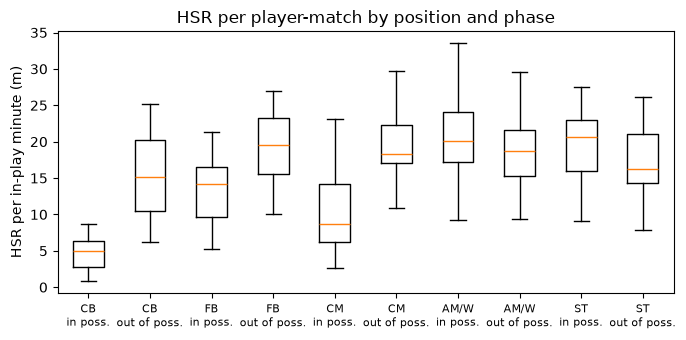

In [14]:
# Outfield player-minutes, one row per player x minute x phase
pm = T.player_minute[T.player_minute.pos_group.notna() & T.player_minute.pos_group.ne("GK")].copy()
pm["phase"] = np.where(pm.in_possession, "offense", "defense")
pm["player_match"] = pm.match + "_" + pm.pID
print(f"{pm.pID.nunique()} outfield players, {pm.player_match.nunique()} player-matches, {len(pm):,} player-minute-phase rows")

# Agreement between load metrics (Spearman, player-minutes)
LOAD = ["dist", "hsr", "sprint", "acc_time", "dec_time", "met_energy"]
display(pm[LOAD].corr(method="spearman").round(2))

# HSR per in-play minute for each player-match, by position group and phase
pmx = pm.groupby(["player_match", "pos_group", "phase"], observed=True).agg(hsr=("hsr", "sum"), n=("n_samples", "sum")).reset_index()
pmx = pmx[pmx.n >= CONFIG["SAMPLE_HZ"] * 60 * 10]   # at least 10 in-play minutes in that phase
pmx["hsr_per_min"] = pmx.hsr / (pmx.n / CONFIG["SAMPLE_HZ"] / 60)
fig, ax = plt.subplots(figsize=(7, 3.5))
order = ["CB", "FB", "CM", "AM/W", "ST"]
data = [pmx[(pmx.pos_group == g) & (pmx.phase == ph)].hsr_per_min for g in order for ph in ("offense", "defense")]
ax.boxplot(data, showfliers=False)
ax.set_xticks(range(1, 11), [f"{g}\n{'in poss.' if ph == 'offense' else 'out of poss.'}" for g in order for ph in ("offense", "defense")], fontsize=8)
ax.set_ylabel("HSR per in-play minute (m)"); ax.set_title("HSR per player-match by position and phase")
plt.tight_layout(); plt.show()

### 5.2 Main analysis
Answer the question with the method described above. Report effect sizes with confidence intervals, in addition to p-values.

In [15]:
def windows(pm, w):
    # Aggregate player-minutes into w-minute windows per player, match, half and phase
    d = pm.assign(win=pm.minute // w)
    keys = ["match", "half", "win", "pID", "player_match", "pos_group", "phase"]
    agg = {c: "sum" for c in LOAD} | {c: "mean" for c in ["voronoi", "voronoi_ball", "dist_ball"]} | {"n_samples": "sum"}
    out = d.groupby(keys, observed=True).agg(agg).reset_index()
    # Load per in-play minute, so windows with little ball-in-play time are comparable
    for c in LOAD:
        out[c] = out[c] / (out.n_samples / CONFIG["SAMPLE_HZ"] / 60)
    return out[out.n_samples >= CONFIG["SAMPLE_HZ"] * 20]   # at least 20 s in play

WIN = {w: windows(pm, w) for w in (1, 5, 15)}

rows = []
for w, d in WIN.items():
    for phase, dp in d.groupby("phase"):
        for y in ("voronoi", "voronoi_ball"):
            r = bramex.within_effect(dp, y, "hsr", group="player_match", cluster="pID")
            rows.append({"window_min": w, "phase": phase, "outcome": y, "control": "none", **r})
            r = bramex.within_effect(dp, y, "hsr", group="player_match", cluster="pID", controls=["dist_ball"])
            rows.append({"window_min": w, "phase": phase, "outcome": y, "control": "dist_ball", **r})
MAIN_A = pd.DataFrame(rows)
MAIN_A.pivot_table(index=["outcome", "control", "phase"], columns="window_min", values="effect").round(3)

window_min                          1       5       15
outcome      control   phase                          
voronoi      dist_ball defense  0.0860  0.1060  0.0450
                       offense  0.0810  0.0470 -0.0110
             none      defense -0.0320  0.0360 -0.0230
                       offense -0.0040 -0.0290 -0.0650
voronoi_ball dist_ball defense  0.1060  0.1130  0.0870
                       offense  0.0500  0.0560 -0.0020
             none      defense  0.2750  0.1920  0.1450
                       offense  0.1920  0.1450  0.0600

### 5.3 Robustness
Check the result in each match separately, with leave-one-match-out, with alternative definitions from the decision log, against a placebo or shuffled comparison, and after correction for multiple tests.

In [16]:
d1 = WIN[1]
rob = []
# (a) Each match separately and leave-one-match-out
for m in sorted(d1.match.unique()):
    for phase in ("offense", "defense"):
        r = bramex.within_effect(d1[(d1.match == m) & (d1.phase == phase)], "voronoi_ball", "hsr", "player_match", "pID")
        rob.append({"test": "single match", "subset": m, "phase": phase, **r})
        r = bramex.within_effect(d1[(d1.match != m) & (d1.phase == phase)], "voronoi_ball", "hsr", "player_match", "pID")
        rob.append({"test": "leave one match out", "subset": f"without {m}", "phase": phase, **r})
# (b) Alternative load metrics
for x in ("dist", "sprint", "met_energy", "acc_time"):
    for phase in ("offense", "defense"):
        r = bramex.within_effect(d1[d1.phase == phase], "voronoi_ball", x, "player_match", "pID")
        rob.append({"test": "load metric", "subset": x, "phase": phase, **r})
# (c) Placebo in time: HSR one and two minutes before and after the minute of control
d1s = d1.sort_values(["player_match", "phase", "half", "win"]).copy()
for lag in (-2, -1, 1, 2):
    d1s[f"hsr_lag{lag}"] = d1s.groupby(["player_match", "phase", "half"]).hsr.shift(lag)
    for phase in ("offense", "defense"):
        r = bramex.within_effect(d1s[d1s.phase == phase], "voronoi_ball", f"hsr_lag{lag}", "player_match", "pID")
        rob.append({"test": "placebo lag (min)", "subset": str(-lag), "phase": phase, **r})
# (d) By position group
for g in ("CB", "FB", "CM", "AM/W", "ST"):
    for phase in ("offense", "defense"):
        r = bramex.within_effect(WIN[5][(WIN[5].pos_group == g) & (WIN[5].phase == phase)], "voronoi_ball", "hsr", "player_match", "pID")
        rob.append({"test": "position group (5 min)", "subset": g, "phase": phase, **r})
ROBUST_A = pd.DataFrame(rob)

# Multiple-testing correction across every test of 5.2 and 5.3
all_p = np.r_[MAIN_A.p.values, ROBUST_A.p.values]
q = bramex.bh_fdr(all_p)
MAIN_A["q"], ROBUST_A["q"] = q[: len(MAIN_A)], q[len(MAIN_A):]
ROBUST_A.pivot_table(index=["test", "subset"], columns="phase", values="effect", sort=False).round(3)

phase                                  offense  defense
test                   subset                          
single match           J03WMX           0.2480   0.3030
                       J03WOH           0.2640   0.2930
                       J03WOY           0.1340   0.2790
                       J03WPY           0.2070   0.2320
                       J03WQQ           0.1900   0.2640
                       J03WR9           0.1410   0.2820
leave one match out    without J03WMX   0.1830   0.2700
                       without J03WOH   0.1810   0.2720
                       without J03WOY   0.2040   0.2750
                       without J03WPY   0.1900   0.2830
                       without J03WQQ   0.1930   0.2780
                       without J03WR9   0.2060   0.2740
load metric            dist             0.2300   0.3610
                       sprint           0.1340   0.1460
                       met_energy       0.2940   0.4070
                       acc_time         0.2900   0.2650
placebo lag (min)      2               -0.0030  -0.0320
                       1               -0.0350  -0.0430
                       -1              -0.0130   0.0230
                       -2              -0.0200  -0.0340
position group (5 min) CB               0.0350   0.1720
                       FB               0.1640   0.2300
                       CM               0.0310   0.1520
                       AM/W             0.2900   0.1910
                       ST               0.2740   0.2430

Event study: what happens to a player's ball-zone control in the seconds around the start of an HSR effort, compared with random moments of the same player.

In [17]:
# Event study at 5 Hz around the start of HSR efforts, compared with random moments of the same player
PRE, POST = 5 * CONFIG["SAMPLE_HZ"], 10 * CONFIG["SAMPLE_HZ"]     # 5 s before, 10 s after
MIN_RUN, QUIET = CONFIG["SAMPLE_HZ"], 5 * CONFIG["SAMPLE_HZ"]     # effort lasts >= 1 s, none in the previous 5 s
SERIES = ["voronoi_ball", "voronoi", "dist_ball"]

def event_windows(s, rng):
    eff, plc = [], []
    out = s[s.pos_group.notna() & s.pos_group.ne("GK")]
    for (m, h, p), g in out.groupby(["match", "half", "pID"], sort=False):
        n = int(g["sample"].max()) + 1
        arr = {c: np.full(n, np.nan, "float32") for c in ["speed", *SERIES]}
        for c in arr:
            arr[c][g["sample"].values] = g[c].values
        poss = np.zeros(n, bool); poss[g["sample"].values] = g.in_possession.values
        fast = np.nan_to_num(arr["speed"]) >= CONFIG["HSR_SPEED"]
        valid = lambda k: k - PRE >= 0 and k + POST < n and not np.isnan(arr["voronoi_ball"][k - PRE:k + POST + 1]).any()
        for k in np.where(fast[1:] & ~fast[:-1])[0] + 1:
            if fast[k:k + MIN_RUN].all() and not fast[max(0, k - QUIET):k].any() and valid(k):
                eff.append({"match": m, "pID": p, "phase": "offense" if poss[k] else "defense",
                            **{c: arr[c][k - PRE:k + POST + 1] for c in SERIES}})
                for _ in range(2):
                    u = int(rng.integers(PRE, max(PRE + 1, n - POST - 1)))
                    if valid(u):
                        plc.append({"match": m, "pID": p, "phase": "offense" if poss[u] else "defense",
                                    **{c: arr[c][u - PRE:u + POST + 1] for c in SERIES}})
    return pd.DataFrame(eff), pd.DataFrame(plc)

EFF, PLC = event_windows(T.samples, RNG)
t_rel = np.arange(-PRE, POST + 1) / CONFIG["SAMPLE_HZ"]

def change(df, col):
    # Mean of +2..+6 s minus mean of -5..-3 s, per window
    M = np.vstack(df[col].values)
    pre = M[:, (t_rel >= -5) & (t_rel <= -3)].mean(1); post = M[:, (t_rel >= 2) & (t_rel <= 6)].mean(1)
    return post - pre

rows = []
for phase in ("offense", "defense"):
    for col in SERIES:
        for name, df in (("effort", EFF), ("random moment", PLC)):
            d = change(df[df.phase == phase], col)
            rows.append({"phase": phase, "series": col, "window": name, "n": len(d), "mean_change": d.mean(),
                         "ci_low": d.mean() - 1.96 * d.std() / np.sqrt(len(d)), "ci_high": d.mean() + 1.96 * d.std() / np.sqrt(len(d))})
EVENT_A = pd.DataFrame(rows)
EVENT_A

,phase,series,window,n,mean_change,ci_low,ci_high
0,offense,voronoi_ball,effort,1178,23.5844,18.8471,28.3216
1,offense,voronoi_ball,random moment,936,-3.0643,-8.0532,1.9246
2,offense,voronoi,effort,1178,-33.9002,-49.0442,-18.7562
3,offense,voronoi,random moment,936,10.7509,-2.4012,23.9030
4,offense,dist_ball,effort,1178,-7.7668,-8.6807,-6.8528
5,offense,dist_ball,random moment,936,0.3131,-0.7574,1.3836
6,defense,voronoi_ball,effort,1599,24.2370,20.8652,27.6088
7,defense,voronoi_ball,random moment,1002,2.0102,-1.3089,5.3293
8,defense,voronoi,effort,1599,-67.2888,-77.4014,-57.1763
9,defense,voronoi,random moment,1002,-11.4112,-21.5999,-1.2225


Fatigue: does a player's HSR per in-play minute fall as the match goes on? Values are deviations from that player's own match average.

In [18]:
# Fatigue: within player-match change of HSR per in-play minute across 15-minute blocks
b = pm.assign(block=pd.cut(pm.minute, [0, 15, 30, 45, 60, 75, 200], right=False,
                           labels=["0-15", "15-30", "30-45", "45-60", "60-75", "75+"]))
per = b.groupby(["player_match", "block"], observed=True).agg(hsr=("hsr", "sum"), n=("n_samples", "sum")).reset_index()
per["hsr_per_min"] = per.hsr / (per.n / CONFIG["SAMPLE_HZ"] / 60)
per["dev"] = per.hsr_per_min - per.groupby("player_match").hsr_per_min.transform("mean")
FATIGUE_A = per.groupby("block", observed=True).dev.agg(["mean", "sem", "count"])
FATIGUE_A

,mean,sem,count
block,,,
0-15,-1.0757,0.4209,120
15-30,0.1296,0.4156,120
30-45,-0.4818,0.5170,121
45-60,1.0636,0.6788,123
60-75,0.7573,0.5265,143
75+,-0.4607,0.4511,146


### 5.4 Figure
One figure a coach can read quickly. The title states the finding and the axes show units.

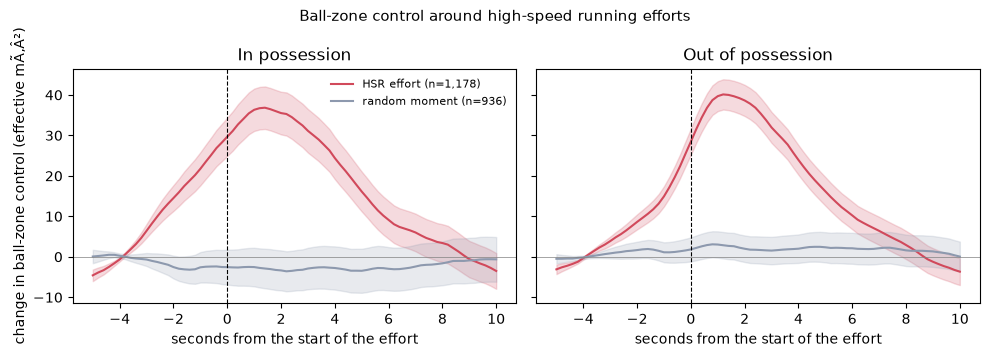

In [19]:
# Ball-zone control around the start of HSR efforts vs random moments (mean and 95% CI, relative to -5..-3 s)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
base = (t_rel >= -5) & (t_rel <= -3)
for ax, phase in zip(axes, ("offense", "defense")):
    for name, df, color in (("HSR effort", EFF, "#d1495b"), ("random moment", PLC, "#8d99ae")):
        M = np.vstack(df[df.phase == phase]["voronoi_ball"].values)
        M = M - M[:, base].mean(1, keepdims=True)
        mu, se = M.mean(0), M.std(0) / np.sqrt(len(M))
        ax.plot(t_rel, mu, color=color, label=f"{name} (n={len(M):,})")
        ax.fill_between(t_rel, mu - 1.96 * se, mu + 1.96 * se, color=color, alpha=0.2)
    ax.axvline(0, color="black", lw=0.8, ls="--"); ax.axhline(0, color="grey", lw=0.5)
    ax.set_title("In possession" if phase == "offense" else "Out of possession")
    ax.set_xlabel("seconds from the start of the effort")
axes[0].set_ylabel("change in ball-zone control (effective mÃ‚Â²)")
axes[0].legend(fontsize=8, frameon=False)
fig.suptitle("Ball-zone control around high-speed running efforts", fontsize=11)
plt.tight_layout(); plt.show()

### 5.5 Features for integration
Variables from this workstream that may help predict the target:
- Keys: `match, half, minute, side` (team level) or the same plus player ID (player level).
- Column names start with `A_`.
- Use only information available up to and including that minute.
- Write a one-line description of each feature.

In [20]:
# Team-minute features from player load, using only that minute's data
f = T.player_minute[T.player_minute.pos_group.ne("GK")].copy()
f["hsr_off"] = np.where(f.in_possession, f.hsr, 0); f["hsr_def"] = np.where(~f.in_possession, f.hsr, 0)
fa = f.groupby(["match", "half", "minute", "side"]).agg(
    A_dist=("dist", "sum"), A_hsr=("hsr", "sum"), A_sprint=("sprint", "sum"), A_met_energy=("met_energy", "sum"),
    A_acc_time=("acc_time", "sum"), A_hsr_off=("hsr_off", "sum"), A_hsr_def=("hsr_def", "sum")).reset_index()
fa["A_hsr_def_share"] = (fa.A_hsr_def / fa.A_hsr.where(fa.A_hsr > 0)).fillna(0)
bramex.register_features("A_team_load", fa, owner="Leonardo", grain="team_minute", descriptions={
    "A_dist": "Team distance covered in the minute, ball in play (m)",
    "A_hsr": "Team high-speed running distance (m)",
    "A_sprint": "Team sprint distance (m)",
    "A_met_energy": "Team metabolic energy (J/kg)",
    "A_acc_time": "Team time above the acceleration threshold (s)",
    "A_hsr_off": "Team HSR distance while in possession (m)",
    "A_hsr_def": "Team HSR distance while out of possession (m)",
    "A_hsr_def_share": "Share of the team's HSR done out of possession",
})
fa.head()

registered A_team_load: 1,122 rows, 8 features (Leonardo)


,match,half,minute,side,A_dist,A_hsr,A_sprint,A_met_energy,A_acc_time,A_hsr_off,A_hsr_def,A_hsr_def_share
0,J03WMX,firstHalf,0,Away,"1,328.2710",102.8340,36.3486,"5,841.4849",14.3600,85.1414,17.6926,0.1721
1,J03WMX,firstHalf,0,Home,"1,405.4745",138.2218,3.1158,"6,264.6987",15.6400,33.5481,104.6737,0.7573
2,J03WMX,firstHalf,1,Away,"1,109.1207",78.5254,0.0000,"4,859.8472",13.8400,0.0000,78.5254,1.0000
3,J03WMX,firstHalf,1,Home,"1,247.2867",137.4986,26.4107,"5,558.5068",16.7200,89.8568,47.6419,0.3465
4,J03WMX,firstHalf,2,Away,"1,150.2007",63.9494,4.6066,"5,416.2988",23.4800,16.9280,47.0214,0.7353


### 5.6 Takeaways
Two or three sentences, each with its evidence label and supporting number. Add each one to the results log (Part 11).

## 6. Workstream B: team possession, progression and defense
Owner: Monica D. Morales-Hernandez

Question: How do possession, ball progression and where a team wins the ball back relate to pitch control?

Fill in before the main analysis:

| | |
|---|---|
| Hypothesis | |
| Unit of analysis | |
| Method | |
| Controls | |
| Rejection rule | What result would make us drop the hypothesis |
| Expected figure | |

Starting points:
- Possession share vs pitch and ball-zone control per minute
- Progression of the ball towards goal per possession
- Location of ball recoveries
- Team running in and out of possession

### 6.1 Exploration
Distributions, outliers and differences between matches and positions. No findings are reported here.

In [21]:
# Exploration


### 6.2 Main analysis
Answer the question with the method described above. Report effect sizes with confidence intervals, in addition to p-values.

In [22]:
# Main analysis


### 6.3 Robustness
Check the result in each match separately, with leave-one-match-out, with alternative definitions from the decision log, against a placebo or shuffled comparison, and after correction for multiple tests.

In [23]:
# Robustness checks


### 6.4 Figure
One figure a coach can read quickly. The title states the finding and the axes show units.

In [24]:
# Main figure


### 6.5 Features for integration
Variables from this workstream that may help predict the target:
- Keys: `match, half, minute, side` (team level) or the same plus player ID (player level).
- Column names start with `B_`.
- Use only information available up to and including that minute.
- Write a one-line description of each feature.

In [25]:
# Feature table and its registration


### 6.6 Takeaways
Two or three sentences, each with its evidence label and supporting number. Add each one to the results log (Part 11).

## 7. Workstream C: chances and possession changes
Owner: Pablo Saraiva

Question: What precedes possession changes, and can their number be predicted seconds ahead?

Pre-registered proposal for team review:

| | |
|---|---|
| Hypothesis | Loss of ball-zone control, backward ball movement, recent pressure and physical load precede possession switches. Past-only shared features will reduce out-of-match MAE relative to a historical-mean baseline. |
| Unit of analysis | A rolling forecast origin within each match and half during active play. The target counts Home/Away possession switches in a future window. |
| Method | Count switches from the original 25 Hz possession flags; align origins to the shared 5 Hz tables; compare a historical mean with regularised Poisson and gradient-boosted count models. |
| Controls | Match, half, time, ball location, current possession duration, recent switches, live-ball share, pitch and ball-zone control, HSR, distance, recent events, plus Monica's possession, progression and possession-start signals recalculated at each origin. |
| Validation | Leave one complete match out, train on five and score on the sixth. No row-level random split and no future information in features. |
| Rejection rule | Do not claim predictive improvement when the match-bootstrap interval for model-minus-baseline MAE includes zero or the model wins in fewer than four of six matches. |
| Expected figure | MAE by candidate horizon and model, plus paired held-out-match differences from the baseline. |

The course forecast horizon is still pending. Results for 30, 60 and 300 seconds are sensitivity checks, not a final horizon selection.


### 7.1 Exploration
Build the target at 25 Hz and attach current and past-only variables from the shared tables. Summarise the target distribution before fitting any model.


In [26]:
from bramex.workstream_c import (
    build_forecast_table, compare_to_baseline, evaluate_feature_ablation, evaluate_models,
    has_workstream_b_features, summarize_scores, team_minute_features,
)

C_OUTPUT = bramex.cache_dir() / "workstream_c"
C_FORECAST_PATH = C_OUTPUT / "forecast_table.csv.gz"
C_FORECAST = pd.read_csv(C_FORECAST_PATH) if C_FORECAST_PATH.exists() else None
if C_FORECAST is None or not has_workstream_b_features(C_FORECAST):
    C_FORECAST = build_forecast_table(T)

C_TARGET_SUMMARY = (
    C_FORECAST.groupby("horizon_seconds")["switches_future"]
    .agg(n="size", mean="mean", std="std", median="median", maximum="max")
)
C_ZERO_SHARE = C_FORECAST.assign(zero=C_FORECAST.switches_future.eq(0)).groupby("horizon_seconds").zero.mean()
C_TARGET_SUMMARY["zero_share"] = C_ZERO_SHARE
C_TARGET_SUMMARY


,n,mean,std,median,maximum,zero_share
horizon_seconds,,,,,,
30,3872,2.0240,1.8455,2.0000,11,0.2193
60,3844,3.7227,2.5744,3.0000,16,0.0624
300,3556,17.1555,6.0037,17.0000,40,0.0000


### 7.2 Main analysis
Compare fixed count models with the required historical-mean baseline. Every score comes from a complete match excluded from training. The ablation contrasts the original C predictors with Monica's B signals recalculated from only the samples available at each forecast origin.


In [27]:
C_ABLATION_PATH = C_OUTPUT / "feature_ablation_lomo.csv"
if C_ABLATION_PATH.exists():
    C_ABLATION = pd.read_csv(C_ABLATION_PATH)
else:
    C_ABLATION = evaluate_feature_ablation(C_FORECAST)
C_SCORES = C_ABLATION[C_ABLATION.feature_set == "C_plus_B"].drop(columns="feature_set")

C_MODEL_SUMMARY = summarize_scores(C_SCORES)
C_MODEL_COMPARISON = C_MODEL_SUMMARY.pivot(
    index="horizon_seconds", columns="model", values="mean_mae"
)[["historical_mean", "poisson", "hist_gradient_boosting"]]
C_ABLATION_SUMMARY = (
    C_ABLATION.groupby(["feature_set", "horizon_seconds", "model"])["mae"]
    .mean().rename("mean_mae").reset_index()
)
display(C_MODEL_COMPARISON)
C_ABLATION_SUMMARY


model,historical_mean,poisson,hist_gradient_boosting
horizon_seconds,,,
30,1.4273,1.4272,1.4484
60,2.0303,2.0327,2.0808
300,4.9311,5.2875,5.6049


,feature_set,horizon_seconds,model,mean_mae
0,C_only,30,hist_gradient_boosting,1.4537
1,C_only,30,historical_mean,1.4273
2,C_only,30,poisson,1.4306
3,C_only,60,hist_gradient_boosting,2.0504
4,C_only,60,historical_mean,2.0303
5,C_only,60,poisson,2.0212
6,C_only,300,hist_gradient_boosting,5.5479
7,C_only,300,historical_mean,4.9311
8,C_only,300,poisson,5.2373
9,C_plus_B,30,hist_gradient_boosting,1.4484


### 7.3 Robustness
Use paired match-level differences, a bootstrap over held-out matches and the number of matches beating baseline. Negative delta MAE favours the model.


In [28]:
C_ROBUSTNESS = compare_to_baseline(C_SCORES)
C_ABLATION_ROBUSTNESS = pd.concat([
    compare_to_baseline(group.drop(columns="feature_set")).assign(feature_set=name)
    for name, group in C_ABLATION.groupby("feature_set")
], ignore_index=True)
display(C_ABLATION_ROBUSTNESS)

C_MATCH_RESULTS = C_SCORES.pivot(
    index=["horizon_seconds", "held_out_match"], columns="model", values="mae"
).reset_index()
C_MATCH_RESULTS["poisson_delta"] = C_MATCH_RESULTS.poisson - C_MATCH_RESULTS.historical_mean
C_MATCH_RESULTS


,horizon_seconds,model,delta_mae_vs_baseline,ci_low,ci_high,matches_beating_baseline,matches_evaluated,feature_set
0,30,hist_gradient_boosting,0.0265,-0.0347,0.0831,2,6,C_only
1,30,poisson,0.0033,-0.0246,0.0314,2,6,C_only
2,60,hist_gradient_boosting,0.0201,-0.0566,0.0851,2,6,C_only
3,60,poisson,-0.0091,-0.0282,0.0152,4,6,C_only
4,300,hist_gradient_boosting,0.6168,0.2604,0.9536,0,6,C_only
5,300,poisson,0.3062,0.0708,0.4833,1,6,C_only
6,30,hist_gradient_boosting,0.0211,-0.0323,0.0697,2,6,C_plus_B
7,30,poisson,-0.0001,-0.0303,0.0285,3,6,C_plus_B
8,60,hist_gradient_boosting,0.0505,0.0174,0.0863,1,6,C_plus_B
9,60,poisson,0.0024,-0.0163,0.0226,3,6,C_plus_B


model,horizon_seconds,held_out_match,hist_gradient_boosting,historical_mean,poisson,poisson_delta
0,30,J03WMX,1.6377,1.5654,1.5905,0.0251
1,30,J03WOH,1.4181,1.3349,1.3817,0.0468
2,30,J03WOY,1.5799,1.4921,1.5196,0.0275
3,30,J03WPY,1.4015,1.4540,1.4005,-0.0535
4,30,J03WQQ,1.3488,1.3453,1.3406,-0.0048
5,30,J03WR9,1.3042,1.3718,1.3303,-0.0416
6,60,J03WMX,2.3784,2.2798,2.2682,-0.0116
7,60,J03WOH,1.9960,1.9692,2.0118,0.0426
8,60,J03WOY,2.1985,2.1648,2.1364,-0.0285
9,60,J03WPY,2.0203,1.9823,1.9629,-0.0193


### 7.4 Figure
The left panel compares mean out-of-match MAE. The right panel shows the paired Poisson difference from baseline for each held-out match at 60 seconds.


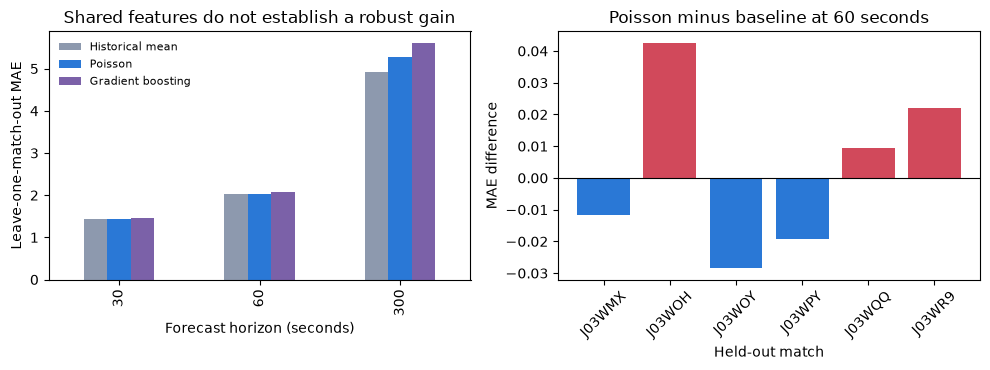

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
C_MODEL_COMPARISON.plot(kind="bar", ax=axes[0], color=["#8d99ae", "#2A78D6", "#7B61A8"])
axes[0].set_title("Shared features do not establish a robust gain")
axes[0].set_xlabel("Forecast horizon (seconds)")
axes[0].set_ylabel("Leave-one-match-out MAE")
axes[0].legend(["Historical mean", "Poisson", "Gradient boosting"], fontsize=8, frameon=False)

c60 = C_MATCH_RESULTS[C_MATCH_RESULTS.horizon_seconds == 60].sort_values("held_out_match")
colors = np.where(c60.poisson_delta < 0, "#2A78D6", "#d1495b")
axes[1].bar(c60.held_out_match, c60.poisson_delta, color=colors)
axes[1].axhline(0, color="black", lw=0.8)
axes[1].set_title("Poisson minus baseline at 60 seconds")
axes[1].set_xlabel("Held-out match")
axes[1].set_ylabel("MAE difference")
axes[1].tick_params(axis="x", rotation=45)
fig.tight_layout()
plt.show()


### 7.5 Features for integration
Register five past-only Workstream C features at team-minute grain. Control momentum is expressed from each side's perspective.


In [30]:
C_TEAM_FEATURES = team_minute_features(C_FORECAST)
bramex.register_features("C_possession_context", C_TEAM_FEATURES, owner="Pablo", grain="team_minute", descriptions={
    "C_recent_switches_30s": "Mean number of active-play possession switches in the previous 30 seconds",
    "C_recent_switches_60s": "Mean number of active-play possession switches in the previous 60 seconds",
    "C_possession_duration_s": "Mean duration of the current uninterrupted possession at forecast origins (s)",
    "C_ball_speed_5s": "Mean five-second ball displacement speed at forecast origins (m/s)",
    "C_control_momentum_5s": "Mean five-second change in ball-zone Voronoi control from the team's perspective",
})

c60 = C_ROBUSTNESS[(C_ROBUSTNESS.horizon_seconds == 60) & (C_ROBUSTNESS.model == "poisson")].iloc[0]
bramex.log_result(
    "C", "Adding leakage-safe Workstream B signals did not establish a robust MAE improvement over the historical baseline",
    "Predictive (out-of-match)", estimate=c60.delta_mae_vs_baseline,
    ci_low=c60.ci_low, ci_high=c60.ci_high, n=c60.matches_evaluated,
    method="C+B ablation; leave-one-match-out; paired bootstrap over matches; provisional 60-second horizon",
)
C_TEAM_FEATURES.head()


registered C_possession_context: 1,094 rows, 5 features (Pablo)


,match,half,minute,C_recent_switches_30s,C_recent_switches_60s,C_possession_duration_s,C_ball_speed_5s,C_control_momentum_5s,side
547,J03WMX,firstHalf,0,1.1000,1.2000,5.3000,6.3806,-0.0554,Away
0,J03WMX,firstHalf,0,1.1000,1.2000,5.3000,6.3806,0.0554,Home
548,J03WMX,firstHalf,1,1.8000,3.5000,12.0040,3.4054,0.0121,Away
1,J03WMX,firstHalf,1,1.8000,3.5000,12.0040,3.4054,-0.0121,Home
549,J03WMX,firstHalf,2,2.2727,4.5455,5.6364,3.5232,-0.0060,Away


### 7.6 Takeaways

- **Descriptive:** the candidate 60-second target averages 3.723 active-play possession switches across 3,844 forecast origins.
- **Predictive out of match, provisional:** C-only Poisson reached MAE 2.021 versus 2.030 for the historical mean at 60 seconds and won in four of six held-out matches. Its paired match-bootstrap interval for the MAE difference was -0.028 to 0.015, so a reliable improvement has not been established.
- **Workstream B integration:** Monica's possession, pitch-control, ball-zone, progression and possession-start signals were recalculated at every origin with no unfinished-minute leakage. C+B Poisson reached MAE 2.033 at 60 seconds (delta +0.002; 95% interval -0.016 to 0.023; three of six wins), so they add context but not incremental forecasting gain.
- **Negative control:** gradient boosting did not beat the historical baseline at any candidate horizon, and the 300-second models were materially worse. Do not open the holdout or freeze a model until the team agrees the official horizon, schema and pitch-control definition.


## 8. Integration
Owner: Leonardo

Delivers: one feature table at team Ãƒâ€” minute level with every registered feature, plus a registry of who built what.

- Player-level features are aggregated to the team (sum or mean, stated by the owner).
- Merge on `match, half, minute, side`. The merge stops on duplicated keys or column names.
- The registry lists: feature set, owner, number of features, description.

In [31]:
# Feature registry


In [32]:
# Merge into one feature table


## 9. Prediction
Owners: Monica (models), Pablo (validation)

Delivers: a model that beats a simple baseline on matches it never saw, frozen before the holdout match is opened.

### 9.1 Target
What we predict, the unit, the horizon and the metric. It must match the course's holdout evaluation (decision D7, W6 task owned by Pablo). Until that is confirmed, build the pipeline with one regression and one classification example.

In [33]:
# Target definition(s)


### 9.2 Supervised table
For each team and half, compute the target over the next *h* minutes and build features from the current and previous minutes only (lags, rolling means). Drop rows without a future value. State *h* and the lags used.

In [34]:
# Supervised table: target ahead, features from the past


### 9.3 Validation protocol
- Leave-one-match-out: train on five matches, score on the sixth, repeat for all six (D8).
- Tune hyperparameters inside the training matches only (nested), never on the held-out match.
- Report the score of each held-out match as well as the average.

In [35]:
# Cross-validation splits


### 9.4 Baselines
A model is useful only if it beats these on held-out matches:
- Training mean (regression) or base rate (classification).
- Persistence: the current value carried forward.

In [36]:
# Baselines


### 9.5 Models
Start with regularised linear or logistic regression, then gradient-boosted trees, then an ensemble of both. Record each model's settings.

In [37]:
# Models


### 9.6 Evaluation and uncertainty
- Regression: MAE, RMSE, RÃ‚Â². Classification: log loss, Brier score, ROC AUC.
- Skill against the baseline, with a bootstrap over held-out matches.
- Number of matches, out of six, where the model beats the baseline.

In [38]:
# Scores per held-out match and bootstrap


### 9.7 Calibration and feature importance
- Calibration: predicted vs observed frequency, held-out predictions only.
- Importance: permutation importance on held-out matches only.

In [39]:
# Calibration


In [40]:
# Permutation importance


### 9.8 Model selection and freeze
Choose the model by held-out performance and record the reason. Fit it on all six matches and save it with the feature list and configuration. After this cell, features, parameters and models do not change (W10 milestone).

In [41]:
# Final fit and freeze


## 10. Holdout inference
Owner: Pablo

Delivers: predictions on the unseen match in the format the course asks for.

Steps:
1. Put the new match's three files in the data folder and open the holdout guard for that match only.
2. Run Parts 2 to 4 for it with the same code and parameters. All checks must pass.
3. Rebuild every workstream's features for it (same definitions as 5.5, 6.5, 7.5).
4. Load the frozen model, predict, and save the file to submit.

In [42]:
# Build tables and features for the holdout match


In [43]:
# Predict with the frozen model and save the submission


## 11. Results log
Owner: all. One row per claim that may go into the presentation. Claims without a row are not presented.

| Column | Content |
|---|---|
| Workstream | A, B, C, Prediction |
| Claim | One sentence |
| Evidence label | One of the five labels |
| Estimate and 95% CI | With units |
| n | Players, minutes, events or matches |
| Method | Short description and the cell where it is computed |

In [44]:
# Results log table
bramex.results_log()


,workstream,claim,evidence,estimate,ci_low,ci_high,n,method
0,C,Adding leakage-safe Workstream B signals did n...,Predictive (out-of-match),0.0024,-0.0163,0.0226,6,C+B ablation; leave-one-match-out; paired boot...


## 12. Conclusions and limitations
Owner: all. Written last, after the team review.

- Answer to the project question in three sentences, with evidence labels.
- What the model can and cannot do on unseen matches.
- Limitations: six matches, five with the same home team, observational data, a simplified pitch-control model, possession from the DFL flag.
- Next steps with more data.